# А/Б тест платёжной воронки

**Цель:** оценить, влияет ли новый вариант платёжной воронки (группа B) на конверсию в успешный платёж по сравнению с контролем (группа A).

**Данные:** файл `case_data.xlsx`, два листа:
* «Пользователи» — user_id, группа теста, возраст, город, тип устройства;
* «Платежи» — payment_id, user_id, группа и время прохождения 4 шагов воронки (открытие, ввод данных, подтверждение, успех).

**План:**
1. Разведочный анализ данных (EDA) и очистка
2. Объединение листов и проверка корректности воронки
3. А/Б тест: валидность эксперимента, основная метрика, воронка по шагам, защитные метрики
4. Итоговый вывод

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

## 1. Разведочный анализ данных (EDA)
Проведем разведочный анализ данных

In [3]:
#Посмотрим названия листов
excel_file = pd.ExcelFile('case_data.xlsx')

excel_file.sheet_names

['Пользователи', 'Платежи']

### 1.1 Лист «Пользователи»

In [4]:
#считаем первую страницу
users = pd.read_excel(excel_file, sheet_name='Пользователи')

users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [5]:
print(f'Размерность датасета "Пользователи":   {users.shape}')

Размерность датасета "Пользователи":   (1504, 5)


In [6]:
users.tail()

,user_id,group,age,city,device_type
1499,2500,B,39,Москва,ios
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


In [7]:
users.sample(5)

,user_id,group,age,city,device_type
1066,2067,B,30,Москва,android
484,1485,A,32,Москва,android
44,1045,A,51,Регион,android
40,1041,A,29,СПб,ios
593,1594,A,26,Москва,android


In [8]:
users.groupby('group').size()

group
A    752
B    751
dtype: int64

In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


In [10]:
users.describe()

,user_id,age
count,1504.000000,1504.000000
mean,1769.787234,32.745346
std,571.592080,8.410915
min,1001.000000,-5.000000
25%,1376.750000,27.000000
50%,1752.500000,33.000000
75%,2128.250000,38.000000
max,9004.000000,150.000000


<Axes: xlabel='age'>

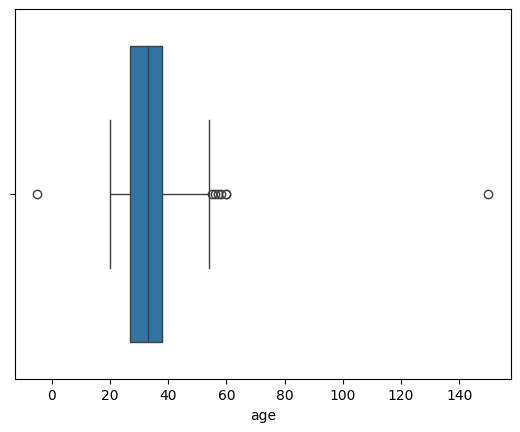

In [11]:
sns.boxplot(data=users, x='age')

In [12]:
users.query('age < 10')

,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android


In [13]:
users.query('age > 90')

,user_id,group,age,city,device_type
1502,9003,B,150,Регион,ios


In [14]:
users = users[~users['user_id'].isin([9002, 9003])]

Обнаружены выбросы. Возраст -5 и 150 невозможен по смыслу — это ошибки ввода/генерации данных, поэтому строки удалены. Возраст >58 валиден: это реальные пользователи из целевой аудитории. IQR пометил их как "выбросы" только потому, что пожилых в выборке мало, а не потому, что они ошибочны. Удалять их нельзя: это сместит выборку и нарушит рандомизацию — мы выкинем часть реальных пользователей, причём, возможно, неравномерно по группам A и B. Поэтому хвост распределения оставлен.

In [15]:
users.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1502 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1502 non-null   int64 
 1   group        1501 non-null   object
 2   age          1502 non-null   int64 
 3   city         1501 non-null   object
 4   device_type  1502 non-null   object
dtypes: int64(2), object(3)
memory usage: 70.4+ KB


In [16]:
users.describe()

,user_id,age
count,1502.000000,1502.000000
mean,1760.156458,32.692410
std,507.303639,7.792696
min,1001.000000,20.000000
25%,1376.250000,27.000000
50%,1751.500000,33.000000
75%,2126.750000,38.000000
max,9004.000000,60.000000


In [17]:
users.query('user_id == 9004')

,user_id,group,age,city,device_type
1503,9004,A,30,NaN,android


Строка с `user_id` = 9004 выбивается из основного диапазона значений, но на данный момент нет оснований удалять эти данные, так как они валидны.

In [18]:
users.isna().sum()

user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

In [19]:
# найдем строку с na в поле group
users[users['group'].isna()]

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


In [20]:
#так как для а/б теста необходимо указание группы - удалим эту строку
users = users[users['group'].notna()]

In [21]:
users.groupby('group').size()

group
A    751
B    750
dtype: int64

In [22]:
users.duplicated().sum()

np.int64(0)

In [23]:
users.user_id.nunique()

1501

In [24]:
#Обновим знания о размерности датасета
print(f'Размерность датасета "Пользователи":   {users.shape}')

Размерность датасета "Пользователи":   (1501, 5)


#### Промежуточный вывод по листу «Пользователи»
В конечном листе «Пользователи» 1501 строка, 5 столбцов;  
Удалены 2 строки с аномальными значениями возраста и 1 строка с пропущенным значением в поле группы;  
Тестовая и контрольная группы схожи по размеру (751 в группе A, 750 в группе B);  
Типы данных указаны в колонках верно;  
1 пропущенное значение в поле city (оставлено, строка не мешает анализу);  
Дубликаты записей отсутствуют, все юзеры уникальные.

### 1.2 Лист «Платежи»

In [25]:
#Перейдем к 2 листу из файла excel
payments = pd.read_excel(excel_file, sheet_name='Платежи')
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [26]:
print(f'Размерность датасета "Платежи":   {payments.shape}')

Размерность датасета "Платежи":   (2661, 7)


In [27]:
payments.tail()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [28]:
payments.sample(5)

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2505,7506,2418.0,B,2024-04-28 15:03:00,2024-04-28 15:09:00,2024-04-28 15:13:00,2024-04-28 15:19:00
2521,7522,2427.0,B,2024-04-24 23:45:00,2024-04-24 23:46:00,2024-04-24 23:50:00,2024-04-24 23:57:00
1178,6179,1685.0,A,2024-04-23 12:39:00,2024-04-23 12:42:00,NaT,NaT
100,5101,1054.0,A,2024-04-06 06:36:00,2024-04-06 06:40:00,2024-04-06 06:44:00,2024-04-06 06:51:00
2524,7525,2428.0,B,2024-04-13 16:32:00,2024-04-13 16:34:00,2024-04-13 16:40:00,2024-04-13 16:45:00


In [29]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB


In [30]:
payments.describe()

,payment_id,user_id,step1_opened,step2_entered,step3_confirmed,step4_success
count,2661.000000,2660.000000,2661,2256,1719,1522
mean,6433.978579,1760.884211,2024-04-15 17:56:46.854565888,2024-04-15 14:21:25.904255488,2024-04-15 13:37:05.375218176,2024-04-15 12:22:53.534822656
min,5001.000000,1001.000000,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
25%,5666.000000,1388.000000,2024-04-08 01:30:00,2024-04-07 22:25:45,2024-04-07 19:01:00,2024-04-07 22:22:00
50%,6331.000000,1762.500000,2024-04-15 15:30:00,2024-04-15 05:12:30,2024-04-15 05:23:00,2024-04-14 23:01:00
75%,6996.000000,2135.250000,2024-04-23 13:25:00,2024-04-23 12:43:00,2024-04-23 14:28:00,2024-04-23 11:49:30
max,99003.000000,9004.000000,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00
std,3203.640974,456.521127,NaN,NaN,NaN,NaN


In [31]:
payments.isna().sum()

payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

In [32]:
payments.nunique()

payment_id         2661
user_id            1501
group                 2
step1_opened       2578
step2_entered      2188
step3_confirmed    1675
step4_success      1489
dtype: int64

In [33]:
payments.duplicated().sum()

np.int64(0)

<Axes: xlabel='payment_id'>

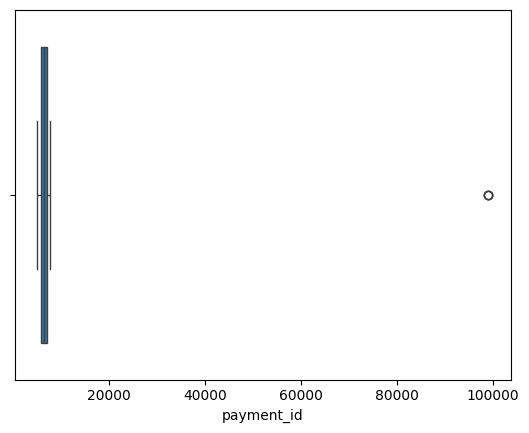

In [34]:
sns.boxplot(data=payments, x='payment_id')

In [35]:
payments.query('payment_id > 90000')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


Строчки с `payment_id` = 99001, 99002, 99003 выбиваются из основного диапазона. Данные в них валидны, поэтому нет оснований убирать эти строки.
* `payment_id` = 99003 не сможет участвовать в мердже (пустой `user_id`), поэтому отпадет сама по себе

<Axes: xlabel='user_id'>

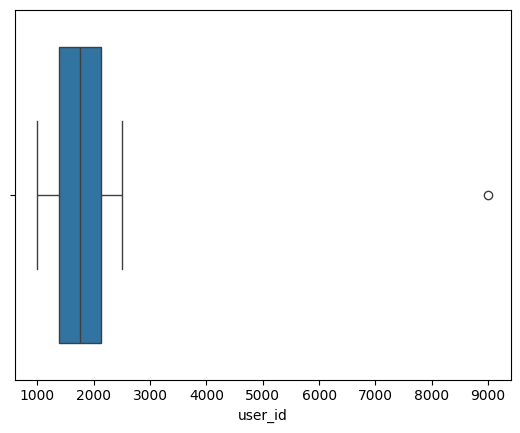

In [36]:
sns.boxplot(data=payments, x='user_id')

In [37]:
payments.query('user_id == 9004')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00


Строка с `user_id` = 9004 тоже выбивается, но данные в ней валидны. Нет оснований убирать эту строчку.

In [38]:
payments.groupby('group').size()

group
A    1309
B    1352
dtype: int64

In [39]:
payments.shape

(2661, 7)

#### Промежуточный вывод по листу «Платежи»
Лист «Платежи» имеет 2661 строку и 7 колонок;  
Дубликатов нет, `payment_id` уникальны;  
1 пропуск в `user_id` (платёж 99003), эта строка отпадет при объединении;  
Пропуски в колонках шагов 2–4 ожидаемы: это платежи, на которых пользователь отвалился;  
Выбросы в `payment_id` (99001–99003) и `user_id` (9004) валидны, оставлены.

### 1.3 Объединение листов

In [40]:
df = payments.merge(users, on='user_id', how='inner') # 1 строку с nan в user_id не берем (это ~0.04% от выборки, не повлияет критично на результат теста)
df.head()

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,A,31,Москва,ios
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,A,31,Москва,ios
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,A,25,Москва,android
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT,A,20,Москва,ios
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,A,20,Москва,ios


In [41]:
df.query('group_x != group_y')

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A,26,Москва,android


Уберем строчку из `df`, где не совпадают группы на разных листах (платёж 99002: в «Платежах» группа B, в «Пользователях» группа A). Уберем лишний столбец с группой.

In [42]:
df = df.query('group_x == group_y')
df = df.drop(columns='group_y')
df = df.rename(columns={'group_x': 'group'})

In [43]:
print(f'Размерность объединенного датасета:   {df.shape}')

Размерность объединенного датасета:   (2659, 10)


### 1.4 Проверка корректности воронки
Проверим, что значения в воронке логичны: нет пропущенных шагов, хронология соблюдена, даты попадают в период теста.

In [44]:
# список колонок с шагами воронки
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
df[steps].dtypes

step1_opened       datetime64[ns]
step2_entered      datetime64[ns]
step3_confirmed    datetime64[ns]
step4_success      datetime64[ns]
dtype: object

In [45]:
# пропуски по шагам (на шагах 2-4 пропуски ожидаемы - это отвалившиеся пользователи)
df[steps].isna().sum()

step1_opened          0
step2_entered       404
step3_confirmed     941
step4_success      1138
dtype: int64

In [46]:
# шаг 1 должен быть заполнен у каждого платежа
df[df['step1_opened'].isna()]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type


Проверим пропущенные шаги: более поздний шаг не может быть заполнен, если предыдущий пуст.

In [47]:
df.query('step3_confirmed.notna() and step2_entered.isna()')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type


In [48]:
df.query('step4_success.notna() and step3_confirmed.isna()')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type


In [49]:
# воронка по количеству: каждый следующий шаг не должен быть больше предыдущего
df[steps].notna().sum()

step1_opened       2659
step2_entered      2255
step3_confirmed    1718
step4_success      1521
dtype: int64

Проверим хронологию: длительность переходов между шагами в минутах.

In [50]:
# длительность переходов между шагами в минутах
df['t_1_2'] = (df['step2_entered'] - df['step1_opened']).dt.total_seconds() / 60
df['t_2_3'] = (df['step3_confirmed'] - df['step2_entered']).dt.total_seconds() / 60
df['t_3_4'] = (df['step4_success'] - df['step3_confirmed']).dt.total_seconds() / 60

df[['t_1_2', 't_2_3', 't_3_4']].describe()

,t_1_2,t_2_3,t_3_4
count,2255.000000,1718.000000,1521.000000
mean,2.393792,4.486612,5.480605
std,1.864095,1.924793,1.053090
min,1.000000,1.000000,1.000000
25%,1.000000,3.000000,5.000000
50%,1.000000,4.000000,6.000000
75%,3.000000,6.000000,6.000000
max,13.000000,11.000000,9.000000


In [51]:
# хронология: следующий шаг не может произойти раньше предыдущего
df.query('t_1_2 < 0')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type,t_1_2,t_2_3,t_3_4


In [52]:
df.query('t_2_3 < 0')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type,t_1_2,t_2_3,t_3_4


In [53]:
df.query('t_3_4 < 0')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type,t_1_2,t_2_3,t_3_4


In [54]:
# нулевые интервалы (два шага в одну и ту же минуту) - подозрительно для ручного ввода данных
df.query('t_1_2 == 0 or t_2_3 == 0 or t_3_4 == 0')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type,t_1_2,t_2_3,t_3_4


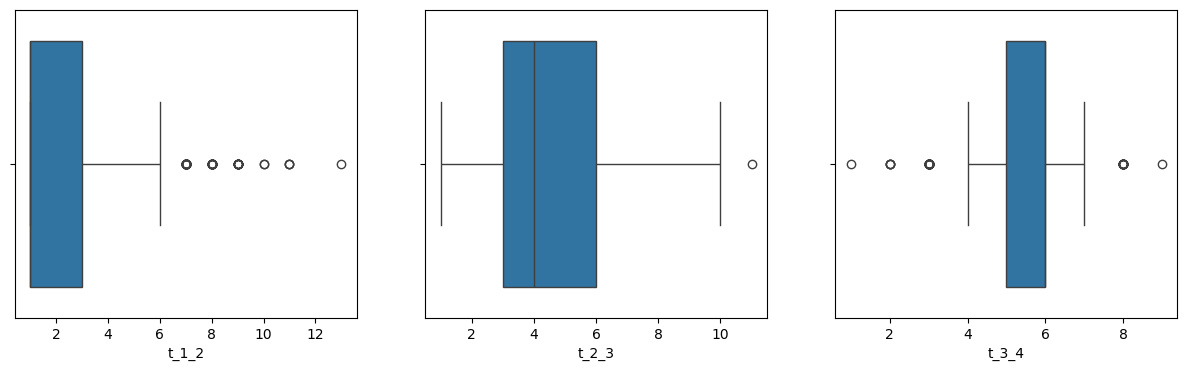

In [55]:
# распределение времени переходов, ищем долгие выбросы
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x='t_1_2', ax=axes[0])
sns.boxplot(data=df, x='t_2_3', ax=axes[1])
sns.boxplot(data=df, x='t_3_4', ax=axes[2])
plt.show()

In [56]:
# переходы, которые боксплот пометил выбросами
df.query('t_1_2 > 9')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type,t_1_2,t_2_3,t_3_4
594,5595,1344.0,A,2024-04-01 07:36:00,2024-04-01 07:47:00,NaT,NaT,36,Москва,ios,11.0,NaN,NaN
1122,6123,1650.0,A,2024-04-03 15:19:00,2024-04-03 15:29:00,NaT,NaT,44,Москва,ios,10.0,NaN,NaN
1719,6720,1973.0,B,2024-04-09 07:22:00,2024-04-09 07:33:00,2024-04-09 07:41:00,2024-04-09 07:46:00,42,Москва,ios,11.0,8.0,5.0
1743,6744,1989.0,B,2024-04-06 05:52:00,2024-04-06 06:03:00,2024-04-06 06:09:00,2024-04-06 06:13:00,30,СПб,android,11.0,6.0,4.0
2319,7320,2321.0,B,2024-04-22 00:55:00,2024-04-22 01:08:00,2024-04-22 01:14:00,2024-04-22 01:19:00,39,Регион,ios,13.0,6.0,5.0
2492,7493,2412.0,B,2024-04-09 14:51:00,2024-04-09 15:01:00,NaT,NaT,40,Москва,android,10.0,NaN,NaN


In [57]:
# все даты должны попадать в период теста (апрель 2024)
print(df[steps].min())
print()
print(df[steps].max())

step1_opened      2024-04-01 00:19:00
step2_entered     2024-04-01 00:23:00
step3_confirmed   2024-04-01 00:29:00
step4_success     2024-04-01 00:33:00
dtype: datetime64[ns]

step1_opened      2024-04-30 23:17:00
step2_entered     2024-04-30 23:20:00
step3_confirmed   2024-04-30 23:25:00
step4_success     2024-04-30 23:30:00
dtype: datetime64[ns]


Проверим, что платежи одного пользователя не пересекаются по времени: новый платёж не может начаться раньше, чем завершился предыдущий.

In [58]:
df = df.sort_values(['user_id', 'step1_opened'])
df['last_step_time'] = df[steps].max(axis=1)
df['prev_end'] = df.groupby('user_id')['last_step_time'].shift()

df.query('step1_opened < prev_end')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type,t_1_2,t_2_3,t_3_4,last_step_time,prev_end
264,5265,1152.0,A,2024-04-29 15:14:00,2024-04-29 15:18:00,2024-04-29 15:20:00,2024-04-29 15:25:00,25,Регион,android,4.0,2.0,5.0,2024-04-29 15:25:00,2024-04-29 15:16:00


In [59]:
# убираем служебные колонки, они больше не нужны
df = df.drop(columns=['last_step_time', 'prev_end'])

#### Промежуточный вывод по воронке
После объединения в `df` осталось 2659 строк из 2661 (убраны платёж без `user_id` и платёж с несовпадением группы);  
Пропущенных шагов нет, воронка монотонна: количество платежей падает от шага к шагу;  
Все переходы хронологически правильные, нулевых и отрицательных интервалов нет;  
Диапазон дат: с 1 по 30 апреля 2024;  
6 переходов «открытие → ввод данных» заняли 10–13 минут. Боксплот пометил их как выбросы, но это реальные, а не ошибочные значения, поэтому они оставлены;  
Платёж 5265 (пользователь 1152) стартовал до завершения предыдущего платежа. Это единственное пересечение, оно не влияет на пользовательскую метрику, поэтому строка оставлена.

## 2. А/Б тест
**Основная метрика:** конверсия пользователя в успешный платёж (доля пользователей, у которых есть хотя бы один `step4_success`).  
Считаем на уровне пользователя, а не платежа: у пользователя в среднем 1,7 платежа, платежи одного человека зависимы, и тест по платежам завысил бы значимость.

**Гипотезы:**  
H0: конверсия в успешный платёж в группах A и B одинакова  
H1: конверсия в группах A и B различается  
Уровень значимости alpha = 0.05

A — контрольная группа, B — тестовая.

### 2.1 Валидность эксперимента

In [60]:
# готовим таблицу на уровне пользователя
user_stats = df.groupby('user_id').agg(n_pay=('payment_id', 'count'),
                                       n_success=('step4_success', 'count')).reset_index()

ab = users.merge(user_stats, on='user_id', how='left')
ab[['n_pay', 'n_success']] = ab[['n_pay', 'n_success']].fillna(0)
ab['success'] = ab['n_success'] > 0

ab.groupby('group').size()

group
A    751
B    750
dtype: int64

SRM (Sample Ratio Mismatch): размеры групп не должны отличаться от ожидаемого 50/50.

In [61]:
# SRM: размеры групп не должны отличаться от 50/50
group_sizes = ab.groupby('group').size()
stats.chisquare(group_sizes)

Power_divergenceResult(statistic=np.float64(0.0006662225183211193), pvalue=np.float64(0.9794078594073907))

p-value = 0.98 > 0.05: группы статистически не отличаются по размеру, рандомизация не нарушена.

In [62]:
# баланс групп по городу и устройству (p > 0.05 - группы сопоставимы)
print(stats.chi2_contingency(pd.crosstab(ab['group'], ab['city']))[1])
print(stats.chi2_contingency(pd.crosstab(ab['group'], ab['device_type']))[1])

0.44037509331857694
0.05950610374415688


Баланс по городу: p-value ≈ 0.44, группы сопоставимы.  
Баланс по устройству: p-value ≈ 0.06, граничный случай (в группе A больше android). Ниже проверим, что эффект теста не держится только на одном типе устройства.

### 2.2 Основная метрика: конверсия в успешный платёж

In [63]:
# конверсия по группам
conv = ab.groupby('group')['success'].agg(['sum', 'count', 'mean'])
#sum - количество успешных сделок, count - объем выборок, mean - конверсия
conv

,sum,count,mean
group,,,
A,493,751,0.656458
B,603,750,0.804000


In [64]:
# z-тест для двух долей
z_stat, p_value = proportions_ztest(conv['sum'].values, conv['count'].values)
print(f'z = {z_stat:.3f}, p-value = {p_value:.2e}')

z = -6.439, p-value = 1.20e-10


In [65]:
# доверительный интервал для разницы конверсий (B - A)
p_a = conv.loc['A', 'mean'] 
p_b = conv.loc['B', 'mean']
n_a = conv.loc['A', 'count']
n_b = conv.loc['B', 'count']

diff = p_b - p_a
se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b) # рассчитали стандартную ошибку разницы двух независимых долей

print(f'Разница CR: {diff:.3%}')
print(f'95% ДИ: [{diff - 1.96 * se:.3%}; {diff + 1.96 * se:.3%}]')

Разница CR: 14.754%
95% ДИ: [10.326%; 19.182%]


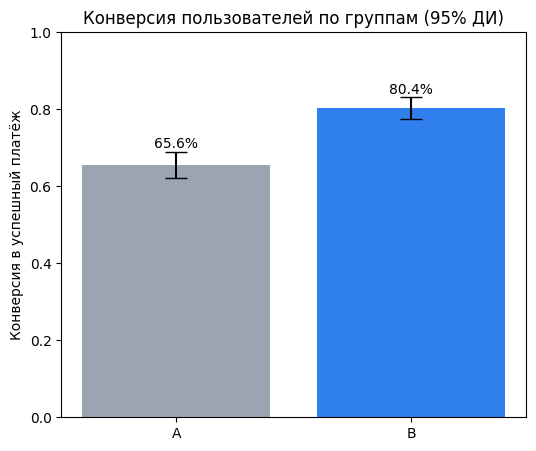

In [66]:
# Посчитаем доверительные интервалы у конверсий групп методом Уилсона
conv_plot = conv.copy()
ci = proportion_confint(conv_plot['sum'], conv_plot['count'], method='wilson')
conv_plot['ci_low'] = ci[0]
conv_plot['ci_high'] = ci[1]
conv_plot['err_low'] = conv_plot['mean'] - conv_plot['ci_low']
conv_plot['err_high'] = conv_plot['ci_high'] - conv_plot['mean']

plt.figure(figsize=(6, 5))
plt.bar(conv_plot.index, conv_plot['mean'], yerr=[conv_plot['err_low'], conv_plot['err_high']],
        capsize=8, color=['#9aa5b1', '#2f80ed'])

# подписи над столбцами
for i, group in enumerate(conv_plot.index):
    plt.text(i, conv_plot.loc[group, 'ci_high'] + 0.01, f"{conv_plot.loc[group, 'mean']:.1%}", ha='center')

plt.ylim(0, 1)
plt.ylabel('Конверсия в успешный платёж')
plt.title('Конверсия пользователей по группам (95% ДИ)')
plt.show()

**Вывод по основной метрике:**  
Конверсия в успешный платёж в группе A — 65,6%, в группе B — 80,4%;  
Разница составляет +14,8 п.п., 95% ДИ разницы: [10,3; 19,2] п.п. — интервал не включает 0;  
z-тест: p-value ≈ 1·10⁻¹⁰ < 0.05, поэтому H0 отвергаем: различие статистически значимо.

### 2.3 Воронка по шагам
Посмотрим, на каких переходах возникает эффект. Считаем на уровне платежей, поэтому результаты вторичные и немного оптимистичны из-за зависимости платежей одного пользователя.

In [67]:
# воронка по шагам для каждой группы (уровень платежей)
funnel = df.groupby('group')[steps].agg(lambda x: x.notna().sum())
funnel

,step1_opened,step2_entered,step3_confirmed,step4_success
group,,,,
A,1308,1061,758,651
B,1351,1194,960,870


In [77]:
# конверсия шаг -> следующий шаг
funnel_conv = pd.DataFrame({
    '1 -> 2': funnel['step2_entered'] / funnel['step1_opened'],
    '2 -> 3': funnel['step3_confirmed'] / funnel['step2_entered'],
    '3 -> 4': funnel['step4_success'] / funnel['step3_confirmed'],
    'итого 1 -> 4': funnel['step4_success'] / funnel['step1_opened']
})
funnel_conv

,1 -> 2,2 -> 3,3 -> 4,итого 1 -> 4
group,,,,
A,0.811162,0.71442,0.858839,0.497706
B,0.883790,0.80402,0.906250,0.643967


In [69]:
# значимость различий на каждом переходе
for a, b in [('step1_opened', 'step2_entered'),
             ('step2_entered', 'step3_confirmed'),
             ('step3_confirmed', 'step4_success')]:
    successes = funnel[b].values
    totals = funnel[a].values
    print(a, '->', b, 'p-value =', proportions_ztest(successes, totals)[1])

step1_opened -> step2_entered p-value = 1.8292887664078748e-07
step2_entered -> step3_confirmed p-value = 6.168281973118032e-07
step3_confirmed -> step4_success p-value = 0.0021956558781369264


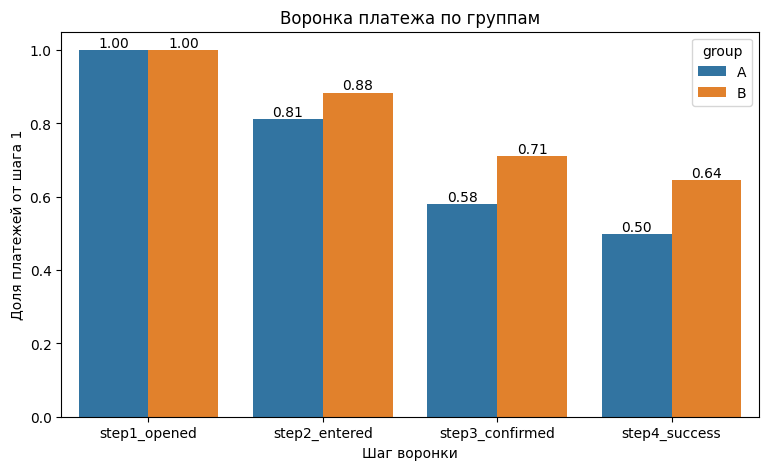

In [76]:
# переводим воронку в доли от шага 1 и приводим к длинному формату для seaborn
funnel_share = funnel.div(funnel['step1_opened'], axis=0).T.reset_index()
funnel_share = funnel_share.melt(id_vars='index', var_name='group', value_name='share')

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=funnel_share, x='index', y='share', hue='group')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')

plt.xlabel('Шаг воронки')
plt.ylabel('Доля платежей от шага 1')
plt.title('Воронка платежа по группам')
plt.show()

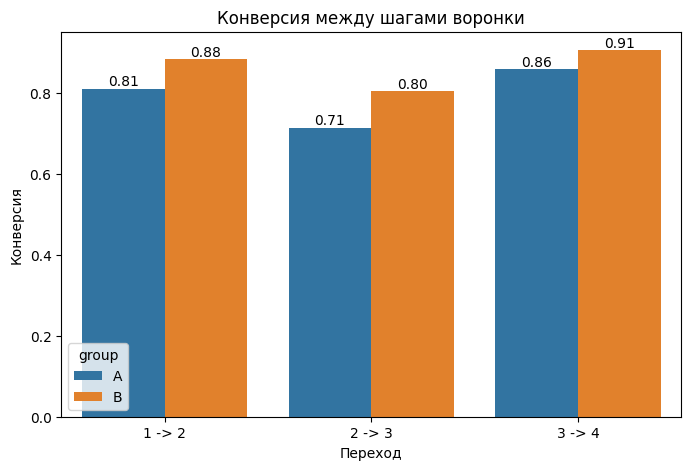

In [80]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=step_conv, x='index', y='conv', hue='group')
for container in ax.containers:
 ax.bar_label(container, fmt='%.2f')
plt.xlabel('Переход')
plt.ylabel('Конверсия')
plt.title('Конверсия между шагами воронки')
plt.show()

**Вывод по воронке:**  
Группа B выигрывает на каждом из трёх переходов:  
* открытие → ввод данных: 81,1% → 88,4% (p < 0.001);  
* ввод данных → подтверждение: 71,4% → 80,4% (p < 0.001);  
* подтверждение → успех: 85,9% → 90,6% (p = 0.002).  

Итоговая конверсия платежа от шага 1 до успеха выросла с 49,8% до 64,4%. Эффект не локален, а проходит через всю воронку, больше всего вырос переход «ввод данных → подтверждение».

### 2.4 Защитная метрика: время прохождения воронки
Проверим, что рост конверсии не достигнут ценой замедления: сравним время от открытия до успешной оплаты.

In [72]:
# общее время прохождения воронки (мин) у успешных платежей
df['t_total'] = (df['step4_success'] - df['step1_opened']).dt.total_seconds() / 60

print(df.groupby('group')['t_total'].describe())
print(stats.mannwhitneyu(df[df['group'] == 'A']['t_total'].dropna(),
                         df[df['group'] == 'B']['t_total'].dropna()))

       count       mean       std  min   25%   50%   75%   max
group                                                         
A      651.0  12.419355  2.673090  6.0  10.5  12.0  14.0  23.0
B      870.0  12.354023  2.907267  5.0  10.0  12.0  14.0  24.0
MannwhitneyuResult(statistic=np.float64(289807.0), pvalue=np.float64(0.43180284403443436))


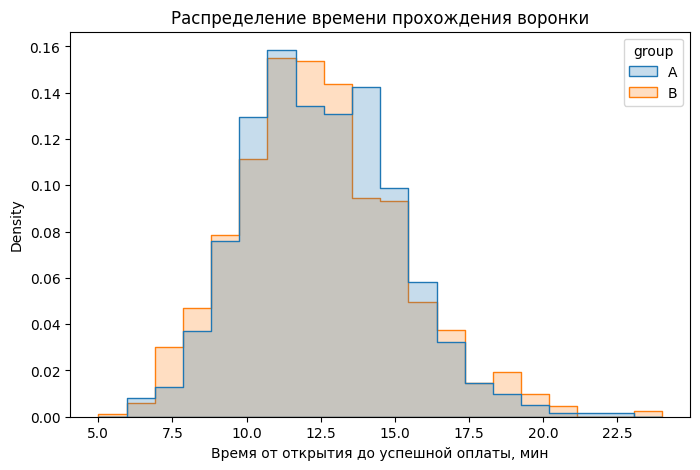

In [73]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df.dropna(subset=['t_total']), x='t_total', hue='group',
             bins=20, stat='density', common_norm=False, element='step')

plt.xlabel('Время от открытия до успешной оплаты, мин')
plt.title('Распределение времени прохождения воронки')
plt.show()

**Вывод по защитной метрике:**  
Медиана времени прохождения воронки 12 минут в обеих группах, распределения почти совпадают;  
Тест Манна — Уитни: p-value = 0.43 > 0.05, значимых различий нет.  
Рост конверсии не достигнут ценой замедления пользователей.

### 2.5 Проверка по сегментам
Группы немного отличаются по составу устройств (p ≈ 0.06), поэтому проверим, что эффект не держится на одном сегменте.

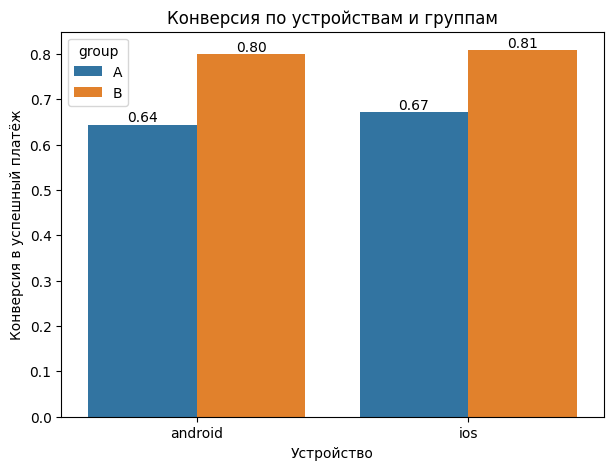

In [74]:
# конверсия в успешный платёж по устройствам и группам
seg = ab.groupby(['device_type', 'group'])['success'].mean().reset_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=seg, x='device_type', y='success', hue='group')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')

plt.xlabel('Устройство')
plt.ylabel('Конверсия в успешный платёж')
plt.title('Конверсия по устройствам и группам')
plt.show()

In [75]:
# конверсия по городам и группам
ab.groupby(['city', 'group'])['success'].mean().unstack()

group,A,B
city,,
Москва,0.625000,0.810458
Регион,0.667910,0.763265
СПб,0.685567,0.844221


**Вывод по сегментам:**  
Эффект сохраняется во всех сегментах:  
* android: 64,4% → 79,9%, ios: 67,2% → 80,8%;  
* Москва: 62,5% → 81,0%, Регион: 66,8% → 76,3%, СПб: 68,6% → 84,4%.  

Граничный дисбаланс по устройствам (p ≈ 0.06) не объясняет результат: прирост одинаков на android и ios.

## 3. Итоговый вывод
**Результат:** вариант B значимо повышает конверсию пользователей в успешный платёж: 65,6% → 80,4% (+14,8 п.п., 95% ДИ [10,3; 19,2] п.п., p-value ≈ 1·10⁻¹⁰).

**Почему результату можно доверять:**
* рандомизация не нарушена: размеры групп 751 и 750, SRM p-value = 0.98;
* группы сопоставимы по городу (p ≈ 0.44) и устройству (p ≈ 0.06, граничный случай, но эффект одинаков на android и ios);
* эффект есть на всех трёх шагах воронки и во всех сегментах;
* защитная метрика (время прохождения воронки) не ухудшилась;
* основной тест считался на уровне пользователей, поэтому зависимость платежей одного человека не завышает значимость.

**Рекомендация:** раскатить вариант B на всех пользователей.

**Ограничения:**
* тест шёл один месяц (апрель 2024), заранее рассчитанного размера выборки нет, мощность можно оценить только постфактум;
* тесты по шагам воронки вторичные, считались на уровне платежей;
* в данных нет суммы платежей, поэтому влияние на выручку и средний чек оценить нельзя;
* из анализа исключены 2 пользователя с невозможным возрастом (-5 и 150), 1 пользователь без группы, платёж без `user_id` и платёж с несовпадением групп. Доля исключённого менее 0,2%, на результат это не влияет.